# Experimentos de complejidad de la etapa 2

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 0, 1 y 2: Cristina.

Este notebook reúne los experimentos de complejidad de las estructuras propias de la etapa 2. Los de la etapa 0 (colas FIFO) están en el paso 8 de `etapa0_ingesta_buffer.ipynb` y los de la etapa 1 (ordenación, búsqueda y deduplicación) en el paso 9 de `etapa1_preprocesamiento.ipynb`. Están aparte del notebook de la etapa porque llegan a 10 millones de elementos y su ejecución completa tarda bastante más que el resto del pipeline.

| Sección | Estructura propia | Líneas base |
| --- | --- | --- |
| 1. Etapa 2 | `MinHeap` (push, pop y `heapify`) | `heapq` y lista ordenada |

## Condiciones comunes

- **Tamaños.** 1K, 10K, 100K, 1M y 10M elementos. Las estructuras con costo O(n) por operación (lista ordenada) se miden solo hasta 100K, porque a 10M tardaría horas.
- **Repeticiones.** 100 para 1K y 10K, 20 para 100K y 5 para 1M. A 10M se hace 1 repetición, porque una sola ejecución tarda más de un minuto. Cada sección justifica sus repeticiones.
- **Medición.** `time.perf_counter`, con el recolector de basura desactivado durante cada medición. La memoria se mide con `tracemalloc` hasta 1M.
- **Datos.** Generados con la semilla 42. En cada tamaño todas las estructuras reciben los mismos datos.
- **Código medido.** Las estructuras se importan de `src/`. Son idénticas a las implementadas paso a paso en los notebooks de cada etapa.
- **Resultados.** Cada experimento guarda sus mediciones en un CSV dentro de `results/`. Si el CSV ya existe, el notebook lo lee en lugar de medir de nuevo; para medir otra vez se cambia `REEJECUTAR_EXPERIMENTOS` a `True`.

In [1]:
import bisect                     # línea base: lista ordenada
import gc
import heapq                      # línea base: heap en C
import platform
import random
import sys
import time
import tracemalloc
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config
from src.etapa_2.stage2_heap import MinHeap

SEED = config.SEED     #42
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS
CARPETA_RESULTADOS.mkdir(exist_ok=True)

REEJECUTAR_EXPERIMENTOS = False   # True mide de nuevo aunque existan los CSV de results/

# Plataforma (el enunciado pide reportarla junto con la semilla)
PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}
PLATAFORMA

{'sistema': 'Windows-11-10.0.26200-SP0',
 'procesador': 'Intel64 Family 6 Model 158 Stepping 10, GenuineIntel',
 'nucleos': 12,
 'ram_gb': 17.0,
 'python': '3.12.3',
 'semilla': 42}

## 1. Etapa 2: min-heap

Se realizan dos experimentos.

| Experimento | Implementación propia | Líneas base | Complejidad esperada |
| --- | --- | --- | --- |
| A. n push seguidos de n pop | `MinHeap` | `heapq` (en C) y lista ordenada (`bisect.insort` y `pop(0)`) | O(n log n) para los heaps, O(n²) para la lista |
| B. Construcción del heap | `heapify` (Floyd) | n push sucesivos y `heapq.heapify` | O(n) frente a O(n log n) |

Condiciones comunes a los dos experimentos.

- **Elementos.** Tuplas `(clase, deadline, seq)` aleatorias con la semilla 42, que tienen la misma forma que las claves reales.
- **Tamaños.** 1K, 10K, 100K, 1M y 10M.
- **Repeticiones.** 100 para 1K y 10K, 20 para 100K, 5 para 1M y 1 para 10M, por el tiempo que toma cada ejecución en Python.
- **Límite de la lista ordenada.** Se mide solo hasta 100K, con 3 repeticiones en ese tamaño, porque cada inserción y cada `pop(0)` desplazan O(n) elementos.
- **Recolector de basura.** Desactivado durante cada medición.
- **Resultados.** Se guardan en CSV dentro de `results/`. Para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True`.

In [10]:
TAMANOS = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
REPETICIONES = {1_000: 100, 10_000: 100, 100_000: 20, 1_000_000: 5, 10_000_000: 1}
LIMITE_LISTA = 100_000


def generar_claves(n):
    rng = random.Random(SEED)
    return [(rng.randint(1, 5), rng.random(), i) for i in range(n)]


def medir(funcion, *args):
    gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        funcion(*args)
        return time.perf_counter() - t0
    finally:
        gc.enable()


def ejecutar_experimento(nombre_csv, metodos, repeticiones_para, generar=generar_claves):
    ruta = CARPETA_RESULTADOS / nombre_csv
    if ruta.exists() and not REEJECUTAR_EXPERIMENTOS:
        print(f"Resultados leídos de {ruta.relative_to(RAIZ)}")
        return pd.read_csv(ruta)
    filas = []
    for n in TAMANOS:
        claves = generar(n)
        for nombre, (funcion, limite_n) in metodos.items():
            if limite_n is not None and n > limite_n:
                continue
            for rep in range(repeticiones_para(nombre, n)):
                filas.append({"metodo": nombre, "n": n, "repeticion": rep, "segundos": medir(funcion, claves)})
        del claves
        print(f"n = {n:>10,} medido")
    resultado = pd.DataFrame(filas)
    resultado.to_csv(ruta, index=False)
    print(f"Resultados guardados en {ruta.relative_to(RAIZ)}")
    return resultado


def resumir(tiempos):
    return (tiempos.groupby(["metodo", "n"])["segundos"]
            .agg(promedio_s="mean", desv_est_s="std", repeticiones="count").reset_index())


def pendientes(resumen, esperado):
    filas = []
    for nombre, datos in resumen.groupby("metodo"):
        k, _ = np.polyfit(np.log10(datos["n"]), np.log10(datos["promedio_s"]), 1)
        filas.append({"metodo": nombre, "pendiente_empirica": round(k, 2), "esperado": esperado[nombre],
                      "rango_n": f"{datos['n'].min():,} a {datos['n'].max():,}"})
    return pd.DataFrame(filas)

### Experimento A. Insertar y extraer

Cada medición inserta n claves y luego extrae las n en orden. Para los heaps se espera O(n log n), es decir, una pendiente log-log entre 1.0 y 1.1. Para la lista ordenada se espera O(n²), con pendiente cercana a 2.

n =      1,000 medido


n =     10,000 medido


n =    100,000 medido


n =  1,000,000 medido


n = 10,000,000 medido
Resultados guardados en results\etapa2_push_pop_tiempos.csv


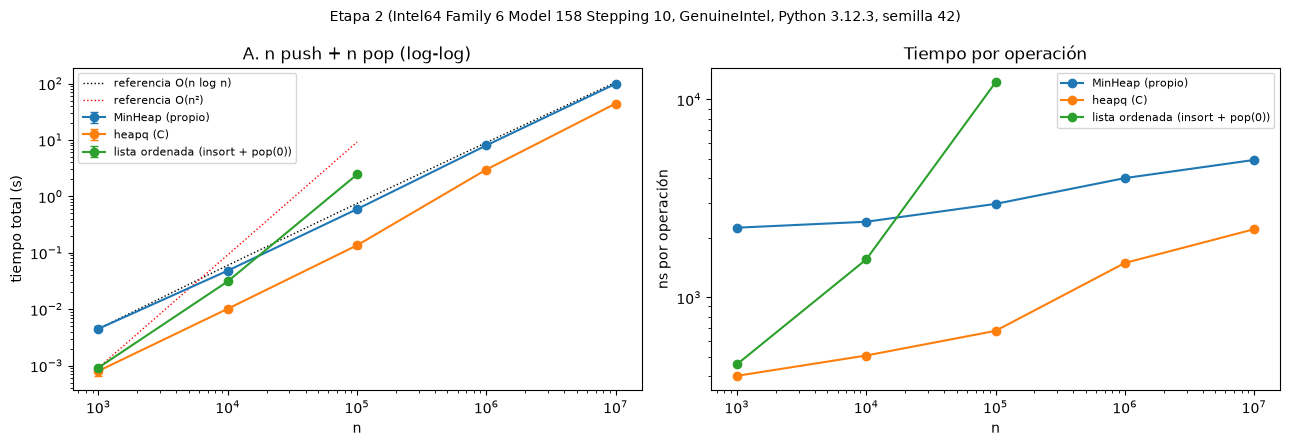

,metodo,n,promedio_s,desv_est_s,repeticiones,ns_por_operacion
0,MinHeap (propio),1000,0.004501,0.000450,100,2250.538001
1,MinHeap (propio),10000,0.048236,0.002544,100,2411.803950
2,MinHeap (propio),100000,0.593685,0.012454,20,2968.426400
3,MinHeap (propio),1000000,8.013837,0.105103,5,4006.918550
4,MinHeap (propio),10000000,98.993211,NaN,1,4949.660530
5,heapq (C),1000,0.000803,0.000145,100,401.720499
6,heapq (C),10000,0.010176,0.000550,100,508.816700
7,heapq (C),100000,0.135551,0.011649,20,677.753675
8,heapq (C),1000000,2.985972,0.005404,5,1492.986080
9,heapq (C),10000000,44.223948,NaN,1,2211.197380


,metodo,pendiente_empirica,esperado,rango_n
0,MinHeap (propio),1.09,≈1.0-1.1 (n log n),"1,000 a 10,000,000"
1,heapq (C),1.19,≈1.0-1.1 (n log n),"1,000 a 10,000,000"
2,lista ordenada (insort + pop(0)),1.71,≈2 (n²),"1,000 a 100,000"


In [11]:
def push_pop_propio(claves):
    h = MinHeap()
    for k in claves:
        h.push(k)
    while len(h):
        h.pop()

def push_pop_heapq(claves):
    h = []
    for k in claves:
        heapq.heappush(h, k)
    while h:
        heapq.heappop(h)

def push_pop_lista_ordenada(claves):
    lista = []
    for k in claves:
        bisect.insort(lista, k)          # O(n): desplaza los elementos mayores
    while lista:
        lista.pop(0)                     # O(n): desplaza todos los demás

tiempos_a = ejecutar_experimento(
    "etapa2_push_pop_tiempos.csv",
    {"MinHeap (propio)": (push_pop_propio, None),
     "heapq (C)": (push_pop_heapq, None),
     "lista ordenada (insort + pop(0))": (push_pop_lista_ordenada, LIMITE_LISTA)},
    lambda nombre, n: min(REPETICIONES[n], 3) if nombre.startswith("lista") and n >= LIMITE_LISTA else REPETICIONES[n])
resumen_a = resumir(tiempos_a)
resumen_a["ns_por_operacion"] = resumen_a["promedio_s"] / (2 * resumen_a["n"]) * 1e9

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, datos in resumen_a.groupby("metodo"):
    ax1.errorbar(datos["n"], datos["promedio_s"], yerr=datos["desv_est_s"], marker="o", capsize=3, label=nombre)
    ax2.plot(datos["n"], datos["ns_por_operacion"], marker="o", label=nombre)
n_ref = np.array(TAMANOS, dtype=float)
base = resumen_a.query("metodo == 'MinHeap (propio)'").iloc[0]
ax1.plot(n_ref, base["promedio_s"] * (n_ref * np.log2(n_ref)) / (base["n"] * np.log2(base["n"])),
         "k:", lw=1, label="referencia O(n log n)")
base_l = resumen_a[resumen_a["metodo"].str.startswith("lista")].iloc[0]
n_l = n_ref[n_ref <= LIMITE_LISTA]
ax1.plot(n_l, base_l["promedio_s"] * (n_l / base_l["n"]) ** 2, "r:", lw=1, label="referencia O(n²)")
for ax, titulo, ylabel in [(ax1, "A. n push + n pop (log-log)", "tiempo total (s)"),
                           (ax2, "Tiempo por operación", "ns por operación")]:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n"); ax.set_ylabel(ylabel); ax.set_title(titulo); ax.legend(fontsize=8)
plt.suptitle(f"Etapa 2 ({PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa2_push_pop.png", dpi=150)
plt.show()

display(resumen_a)
pendientes(resumen_a, {"MinHeap (propio)": "≈1.0-1.1 (n log n)", "heapq (C)": "≈1.0-1.1 (n log n)",
                       "lista ordenada (insort + pop(0))": "≈2 (n²)"})

### Experimento B. Construcción del heap

Se construye un heap con n claves de dos formas. La primera inserta las claves una por una con `push` y la segunda aplica `heapify` de Floyd sobre el arreglo completo.

La comparación se hace con dos órdenes de entrada, porque el costo de `push` depende de los datos.

- **Claves aleatorias (caso promedio).** Un elemento nuevo sube en promedio menos de dos niveles, porque la mitad de los nodos de un heap son hojas y la mayoría de los elementos ya es mayor que su padre. Por eso n `push` con datos aleatorios cuestan O(n) en promedio, aunque su cota sea O(n log n).
- **Claves en orden decreciente (peor caso).** Cada clave nueva es menor que todas las anteriores y sube hasta la raíz, recorriendo ⌊log₂ k⌋ niveles. El costo total es Θ(n log n).

`heapify` cuesta O(n) en los dos casos. Si es lineal, su tiempo por elemento se mantiene constante al crecer n, mientras que el de los `push` en el peor caso crece con log n. Esta garantía justifica usar `heapify` en las pasadas de aging, donde las claves cambian de forma arbitraria.

n =      1,000 medido


n =     10,000 medido


n =    100,000 medido


n =  1,000,000 medido


n = 10,000,000 medido
Resultados guardados en results\etapa2_heapify_tiempos.csv


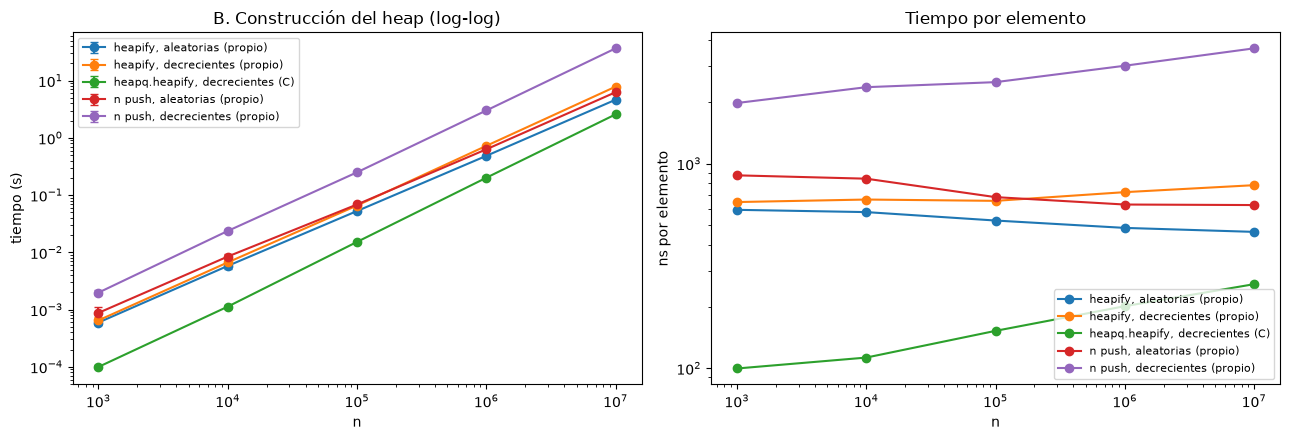

,metodo,n,promedio_s,desv_est_s,repeticiones,ns_por_elemento
0,"heapify, aleatorias (propio)",1000,0.000594,0.000065,100,594.029000
1,"heapify, aleatorias (propio)",10000,0.005790,0.000596,100,579.032400
2,"heapify, aleatorias (propio)",100000,0.052659,0.001797,20,526.591750
3,"heapify, aleatorias (propio)",1000000,0.484707,0.020342,5,484.707480
4,"heapify, aleatorias (propio)",10000000,4.634606,NaN,1,463.460620
5,"heapify, decrecientes (propio)",1000,0.000648,0.000080,100,648.356999
6,"heapify, decrecientes (propio)",10000,0.006670,0.000364,100,666.966800
7,"heapify, decrecientes (propio)",100000,0.065719,0.001160,20,657.192100
8,"heapify, decrecientes (propio)",1000000,0.724826,0.011295,5,724.825980
9,"heapify, decrecientes (propio)",10000000,7.840234,NaN,1,784.023360


,metodo,pendiente_empirica,esperado,rango_n
0,"heapify, aleatorias (propio)",0.97,≈1 (n),"1,000 a 10,000,000"
1,"heapify, decrecientes (propio)",1.02,≈1 (n),"1,000 a 10,000,000"
2,"heapq.heapify, decrecientes (C)",1.11,≈1 (n),"1,000 a 10,000,000"
3,"n push, aleatorias (propio)",0.96,"≈1 (n, caso promedio)","1,000 a 10,000,000"
4,"n push, decrecientes (propio)",1.06,"≈1.0-1.1 (n log n, peor caso)","1,000 a 10,000,000"


In [12]:
def generar_claves_dos_ordenes(n):
    claves = generar_claves(n)
    return claves, sorted(claves, reverse=True)      # (aleatorias, decrecientes)

def push_aleatorias(datos):
    h = MinHeap()
    for k in datos[0]:
        h.push(k)

def push_decrecientes(datos):
    h = MinHeap()
    for k in datos[1]:
        h.push(k)

def heapify_aleatorias(datos):
    MinHeap(datos[0])

def heapify_decrecientes(datos):
    MinHeap(datos[1])

def heapq_heapify_decrecientes(datos):
    heapq.heapify(list(datos[1]))

tiempos_b = ejecutar_experimento(
    "etapa2_heapify_tiempos.csv",
    {"n push, aleatorias (propio)": (push_aleatorias, None),
     "n push, decrecientes (propio)": (push_decrecientes, None),
     "heapify, aleatorias (propio)": (heapify_aleatorias, None),
     "heapify, decrecientes (propio)": (heapify_decrecientes, None),
     "heapq.heapify, decrecientes (C)": (heapq_heapify_decrecientes, None)},
    lambda nombre, n: REPETICIONES[n],
    generar=generar_claves_dos_ordenes)
resumen_b = resumir(tiempos_b)
resumen_b["ns_por_elemento"] = resumen_b["promedio_s"] / resumen_b["n"] * 1e9

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, datos in resumen_b.groupby("metodo"):
    ax1.errorbar(datos["n"], datos["promedio_s"], yerr=datos["desv_est_s"], marker="o", capsize=3, label=nombre)
    ax2.plot(datos["n"], datos["ns_por_elemento"], marker="o", label=nombre)
for ax, titulo, ylabel in [(ax1, "B. Construcción del heap (log-log)", "tiempo (s)"),
                           (ax2, "Tiempo por elemento", "ns por elemento")]:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n"); ax.set_ylabel(ylabel); ax.set_title(titulo); ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa2_heapify.png", dpi=150)
plt.show()

display(resumen_b)
pendientes(resumen_b, {"n push, aleatorias (propio)": "≈1 (n, caso promedio)",
                       "n push, decrecientes (propio)": "≈1.0-1.1 (n log n, peor caso)",
                       "heapify, aleatorias (propio)": "≈1 (n)",
                       "heapify, decrecientes (propio)": "≈1 (n)",
                       "heapq.heapify, decrecientes (C)": "≈1 (n)"})

### Memoria

Se mide con `tracemalloc` la memoria pico de insertar n claves y extraerlas, hasta 1M. Las claves se generan antes de la medición, así que la cifra corresponde solo a la estructura. Se espera que todas usen unos 8 bytes por elemento, porque las tres guardan una referencia por elemento en un arreglo.

In [13]:
ruta_memoria = CARPETA_RESULTADOS / "etapa2_memoria.csv"
if ruta_memoria.exists() and not REEJECUTAR_EXPERIMENTOS:
    memoria = pd.read_csv(ruta_memoria)
else:
    filas = []
    for n in [1_000, 10_000, 100_000, 1_000_000]:
        claves = generar_claves(n)
        for nombre, funcion in [("MinHeap (propio)", push_pop_propio), ("heapq (C)", push_pop_heapq),
                                ("lista ordenada (insort + pop(0))", push_pop_lista_ordenada)]:
            if nombre.startswith("lista") and n > LIMITE_LISTA:
                continue
            gc.collect()
            tracemalloc.start()
            funcion(claves)
            _, pico = tracemalloc.get_traced_memory()
            tracemalloc.stop()
            filas.append({"metodo": nombre, "n": n, "pico_mb": pico / 1e6})
    memoria = pd.DataFrame(filas)
    memoria.to_csv(ruta_memoria, index=False)

memoria["bytes_por_elemento"] = memoria["pico_mb"] * 1e6 / memoria["n"]
memoria.pivot(index="n", columns="metodo", values="bytes_por_elemento").round(1)

metodo,MinHeap (propio),heapq (C),lista ordenada (insort + pop(0))
n,,,
1000,9.1,8.9,8.9
10000,8.5,8.5,8.5
100000,8.0,8.0,8.0
1000000,8.6,8.4,NaN


### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada en `results/`, con Python 3.12. Al medir de nuevo pueden variar ligeramente.

- **Experimento A, heaps.** `MinHeap` tiene una pendiente de 1.09, coherente con O(n log n). Su tiempo por operación pasa de unos 2 250 ns a 1K a unos 4 950 ns a 10M, un aumento de 2.2 veces, muy parecido al de log₂ n, que pasa de 10 a 23 (2.3 veces).
- **Experimento A, `heapq`.** Es unas 5.6 veces más rápido que `MinHeap` a 1K, porque está escrito en C, pero solo 2.2 veces más rápido a 10M. Su pendiente (1.19) es mayor que la del heap propio porque su costo por operación es tan bajo que el acceso a memoria pasa a dominar. Con n grande, el límite lo pone la jerarquía de memoria y no el lenguaje.
- **Experimento A, lista ordenada.** Su pendiente es 1.71 y su tiempo por operación crece unas 27 veces de 1K a 100K, de unos 460 a 12 200 ns. Esto confirma el costo O(n) de cada operación. La pendiente es menor que 2 porque el desplazamiento de elementos lo hace `memmove` en C, que es muy rápido con n pequeño. A 100K ya es 4 veces más lenta que `MinHeap` y la diferencia crece con n.
- **Experimento B.** Con claves aleatorias, n `push` y `heapify` son lineales (pendientes 0.96 y 0.97), como predice el análisis del caso promedio. Con claves decrecientes, el tiempo por elemento de los `push` crece de unos 1 980 a 3 660 ns, mientras que el de `heapify` solo pasa de 650 a 780 ns (pendientes 1.06 y 1.02). A 10M construir con `push` cuesta 4.7 veces más que con `heapify` (37 s frente a 7.8 s).
- **Memoria.** Las tres estructuras usan entre 8 y 9 bytes por elemento, una referencia por posición del arreglo. El heap no tiene costo de memoria adicional frente a una lista.

El heap propio cumple las complejidades teóricas. Se mantiene en la etapa 2 porque la cola de prioridades es una estructura evaluada del proyecto y porque el aging necesita acceder al arreglo interno para recalcular las claves y aplicar `heapify`. `heapq` queda como referencia de lo que se ganaría con una implementación en C.

## 2. Resumen

Todas las estructuras propias cumplen su complejidad teórica de 1K a 10M. Las líneas base escritas en C son más rápidas por un factor constante, pero no cambian el orden; las alternativas con peor orden se alejan cada vez más al crecer n.

| Etapa | Estructura propia | Complejidad | Pendiente medida | Alternativa | Pendiente |
| --- | --- | --- | --- | --- | --- |
| 2 | `MinHeap` (n push y n pop) | O(n log n) | 1.09 | lista ordenada | 1.71 |
| 2 | `heapify` de Floyd, peor caso | O(n) | 1.02 | n `push`, peor caso | 1.06 |

Los resultados de las colas de la etapa 0 están en el paso 8 de `etapa0_ingesta_buffer.ipynb`, y los de la ordenación, la búsqueda y la deduplicación de la etapa 1, en el paso 9 de `etapa1_preprocesamiento.ipynb`.

La pendiente es la del tiempo total en escala log-log: cerca de 1 indica un costo lineal (o n log n, que en este rango da entre 1.0 y 1.1), cerca de 2 un costo cuadrático y cerca de 0 un costo logarítmico.